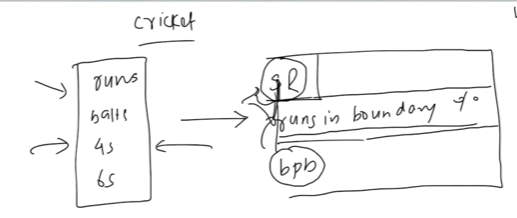

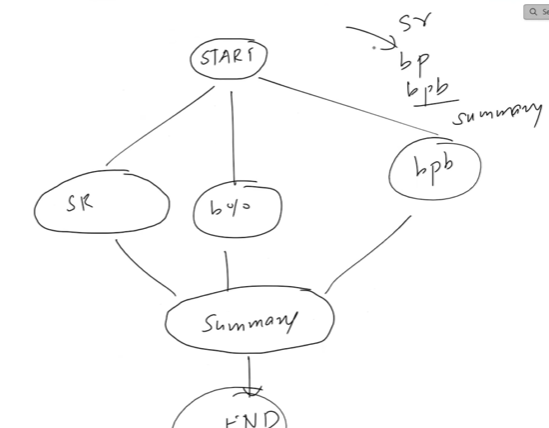

In [3]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict 

In [4]:
class Batsman(TypedDict):
    runs : int
    balls : int
    fours : int
    sixes : int

    sr : float
    bpb : float
    boundary_percent : float
    summary : str
   

### note : functions me puri state return nhi krenge kyoki sbhi parallel ke liye saari states update ho jayengi isliye jis state me changes hue h bss vo return kro

In [5]:
def calc_sr(state : Batsman):
    sr = (state['runs']/state['balls'])*100
    return {'sr': sr}

In [6]:
def calc_bpb(state: Batsman):
    bpb = (state['balls']/(state['fours'] + state['sixes']))
    return {'bpb': bpb}


In [7]:
def calc_boundary_percent(state: Batsman):

    boundary_percent = (((state['fours'] * 4) + (state['sixes'] * 6))/state['runs'])*100

    return {'boundary_percent': boundary_percent}

In [8]:
def summary(state: Batsman):

    summary = f"""
Strike Rate - {state['sr']} \n
Balls per boundary - {state['bpb']} \n
Boundary percent - {state['boundary_percent']}
"""
    
    return {'summary': summary}

In [9]:
graph = StateGraph(Batsman)

graph.add_node('calc_sr',calc_sr)
graph.add_node('calc_bpb',calc_bpb)
graph.add_node('calc_boundary_percent', calc_boundary_percent)
graph.add_node('summary', summary)


graph.add_edge(START,'calc_sr')
graph.add_edge(START,'calc_bpb')
graph.add_edge(START,'calc_boundary_percent')


graph.add_edge('calc_sr','summary')
graph.add_edge('calc_bpb','summary')
graph.add_edge('calc_boundary_percent','summary')


graph.add_edge('summary',END)

workflow = graph.compile()


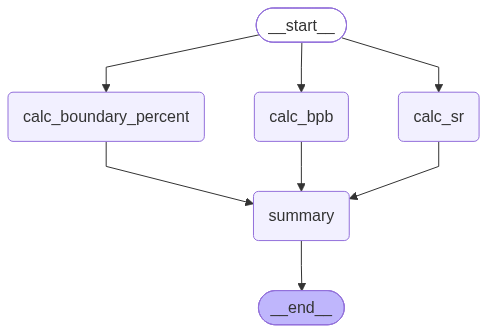

In [10]:
workflow

In [11]:
intial_state = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

workflow.invoke(intial_state)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'boundary_percent': 48.0,
 'summary': '\nStrike Rate - 200.0 \n\nBalls per boundary - 5.0 \n\nBoundary percent - 48.0\n'}

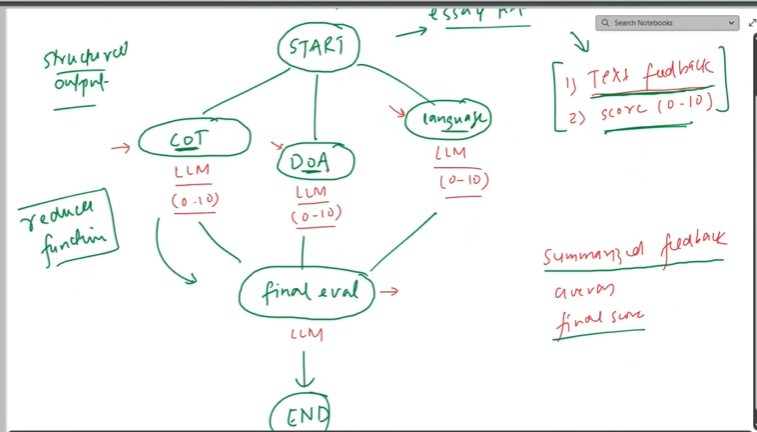

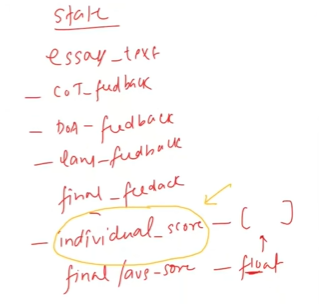

In [12]:
from langgraph.graph import START,END, StateGraph
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from typing import TypedDict,Annotated
from pydantic import BaseModel,Field
import operator

In [13]:
load_dotenv()
model = ChatGroq(model ="openai/gpt-oss-120b")

hume output structured chhaiye isliye structoutput use krenge schema define krne ke liye 

In [26]:
class EvaluationSchema(BaseModel):
    feedback : str = Field(description='detailed feedback of the essay')
    score : float = Field(description='score out of 10', ge=0,le=10)

In [27]:
structured_model = model.with_structured_output(EvaluationSchema)

In [28]:
essay ="""
Capitalism: Meaning, Advantages and Challenges
Capitalism is an economic system in which the means of production are mostly owned by private individuals and companies. In this system, people are free to start businesses, invest money and earn profits. The main objective of capitalism is to increase production, encourage competition and promote economic growth.

Capitalism has played an important role in the development of many countries. It encourages innovation and entrepreneurship. People get opportunities to start their own businesses and improve their standard of living. Competition among companies also helps in improving the quality of goods and services. Countries like the USA have developed a strong economy with the help of a capitalist system.

However, capitalism also has some disadvantages. It can increase the gap between rich and poor people. Wealth and resources may become concentrated in the hands of a few individuals. Sometimes companies focus more on profit rather than the welfare of workers and society. It can also lead to exploitation of labour and environmental degradation.

In India, we follow a mixed economic model where both private and public sectors play an important role. After the economic reforms of 1991, India adopted more liberalisation and encouraged private investment. This helped in economic growth, foreign investment and expansion of industries. However, problems like unemployment, poverty and inequality still exist.

In my opinion, capitalism is important for economic development, but it should not be completely free from government regulation. The government should ensure social justice, equal opportunities and protection of weaker sections of society.

Conclusion: Capitalism can be a useful tool for economic growth, but development should not be measured only in terms of profit and GDP. It should also focus on equality, human dignity and the welfare of all sections of society.





"""

In [38]:
essay2 = """ 
Capitalism is a system of economy in which people earn money by doing business. In this system people can open shop, company and factory. Everyone want to earn more money and become rich. Money is very important in capitalism.

Capitalism is good because people get freedom to do business. If someone have money he can invest and earn more money. Many big companies like Apple and Google are example of capitalism. They give jobs to many people and help country to grow.

But capitalism is also not good in some ways. Rich people become more rich and poor people remain poor. Some companies only think about money and not about people. They also give less salary to workers. So there is inequality in society.

India is also following capitalism but government also run many things. In India both private and government companies are working. This is called mixed economy. After 1991 many changes happened in Indian economy.

I think capitalism is good but not fully good. Government should make rules so that rich people do not exploit poor people. Everyone should get equal chance to earn money.

In last, capitalism is a good system for development but it also have many problems. We should use it in a good way for making India a developed country. 

"""

In [29]:
prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'
structured_model.invoke(prompt)

EvaluationSchema(feedback='The essay presents a clear, logical structure with an introduction, body paragraphs, a personal opinion, and a conclusion. The language is generally understandable and the ideas are organized in a coherent sequence. However, several language‑related issues lower the overall quality:\n\n1. **Repetitive phrasing and word choice** – Phrases such as “important role,” “encourages innovation and entrepreneurship,” and “important role” are repeated, and synonyms could improve variety.\n2. **Grammatical inaccuracies** – Minor errors include missing articles (“the means of production are mostly owned”), inconsistent verb tense (“countries like the USA have developed a strong economy with the help of a capitalist system” could be tighter), and subject‑verb agreement (“the government should ensure social justice, equal opportunities and protection of weaker sections of society” – the list is fine, but the preceding clause could be smoother).\n3. **Punctuation and capita

In [30]:
class UPSCState(TypedDict):

    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[float], operator.add]
    avg_score: float

In [31]:
def evaluate_language(state : UPSCState):
    prompt =f'Evaluate the language quality of the essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'language_feedback': output.feedback, 'individual_scores':[output.score]}

In [32]:
def evaluate_analysis(state: UPSCState):

    prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'analysis_feedback': output.feedback, 'individual_scores': [output.score]}


In [33]:
def evaluate_thought(state: UPSCState):

    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}


In [34]:
def final_evaluation(state: UPSCState):

    # summary feedback
    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'
    overall_feedback = model.invoke(prompt).content

    # avg calculate
    avg_score = sum(state['individual_scores'])/len(state['individual_scores'])

    return {'overall_feedback': overall_feedback, 'avg_score': avg_score}


In [35]:
graph = StateGraph(UPSCState)

graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('final_evaluation', final_evaluation)

# edges
graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought')

graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_thought', 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow = graph.compile()


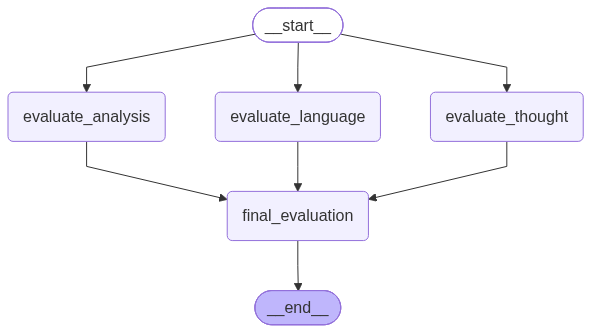

In [36]:
workflow

In [39]:
intial_state = {
    'essay': essay2
}

workflow.invoke(intial_state)

{'essay': ' \nCapitalism is a system of economy in which people earn money by doing business. In this system people can open shop, company and factory. Everyone want to earn more money and become rich. Money is very important in capitalism.\n\nCapitalism is good because people get freedom to do business. If someone have money he can invest and earn more money. Many big companies like Apple and Google are example of capitalism. They give jobs to many people and help country to grow.\n\nBut capitalism is also not good in some ways. Rich people become more rich and poor people remain poor. Some companies only think about money and not about people. They also give less salary to workers. So there is inequality in society.\n\nIndia is also following capitalism but government also run many things. In India both private and government companies are working. This is called mixed economy. After 1991 many changes happened in Indian economy.\n\nI think capitalism is good but not fully good. Gover